# Pennylane Giriş - Kuantum Hesaplama Kodlama oturumu

In [1]:
!pip install pennylane

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 32.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 12.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 83.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 53.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 73.5 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


## Pennylane kütüphanesini İmport etme ve gerekli bağımlılıkları indirme

In [40]:
import pennylane as qml
from pennylane import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Mantık Kapılarını Tanıyalım

In [41]:
qml.device("default.qubit", wires=3)
qml.Hadamard(wires=0)
qml.PauliX(wires=0)
qml.PauliZ(wires=0)
qml.PauliY(wires=0)
qml.Rot(np.pi/2, np.pi/2, np.pi/2, wires=0)
qml.CNOT(wires=[0, 1])
qml.Toffoli(wires=[0, 1, 2])

Toffoli(wires=[0, 1, 2])

## İlk Devremizi Oluşturalım

In [4]:
#Pennylane Device oluşturma
qml_device = qml.device('default.qubit', wires=2)

@qml.qnode(qml_device)
def quantum_circuit():
    """

     Örnek bir devre fonksiyonu

    """
    return qml.state()

## Hello Quantum World

In [20]:
@qml.qnode(qml_device)
def bell_circuit():
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0, 1])
    print("Hello Quantum World")
    return qml.state()

bell_circuit()

Hello Quantum World


array([0.70710678+0.j, 0.        +0.j, 0.        +0.j, 0.70710678+0.j])

In [14]:
# Ölçüm yapabilmek için finite shots (atış sayısı) içeren yeni bir cihaz tanımlıyoruz
measurement_device = qml.device('default.qubit', wires=2, shots=10)

@qml.qnode(measurement_device)
def bell_circuit_with_measurement():
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0, 1])
    # 10 adet örnek ölçüm sonucu döndürüyoruz (her biri için [bit_0, bit_1])
    return qml.sample(wires=[0, 1])

# Devreyi çalıştırıp ölçüm sonuçlarını gözlemliyoruz
print("Ölçüm Örnekleri:")
print(bell_circuit_with_measurement())

Ölçüm Örnekleri:
[[1 1]
 [1 1]
 [1 1]
 [0 0]
 [0 0]
 [1 1]
 [1 1]
 [0 0]
 [1 1]
 [0 0]]


Hello Quantum World


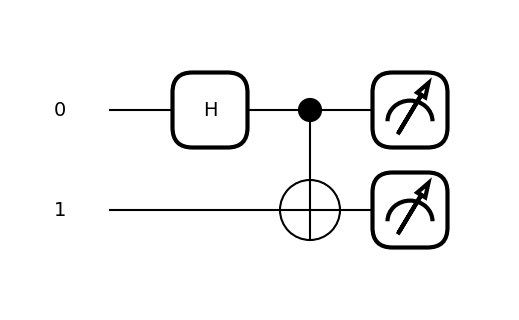

In [42]:
import matplotlib.pyplot as plt

# Bell devresini çizdiriyoruz
fig, ax = qml.draw_mpl(bell_circuit)()
plt.show()

/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


Gerçekleşen Ölçüm Sonucu: Qubit 0 = 1, Qubit 1 = 1


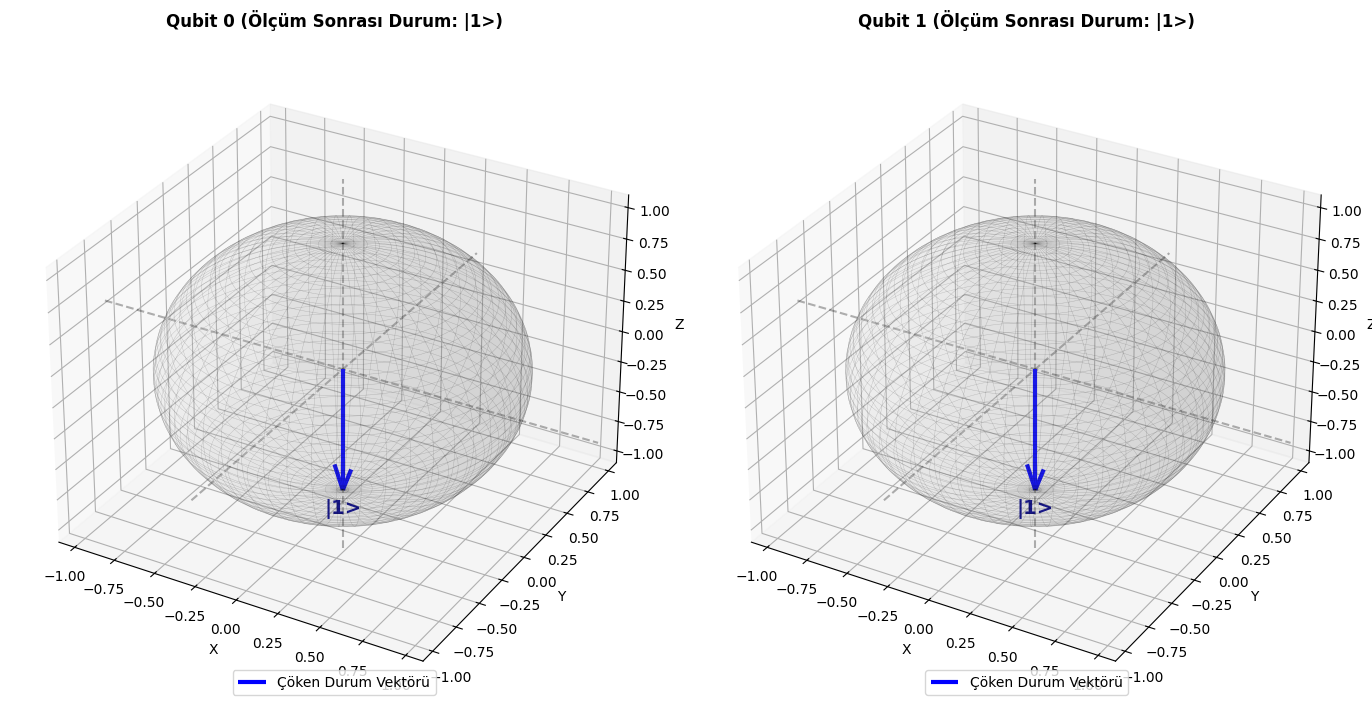

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pennylane as qml

# Ölçüm yapabilen cihaz
measurement_device = qml.device('default.qubit', wires=2, shots=1)

@qml.qnode(measurement_device)
def sample_bell_measurement():
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0, 1])
    return qml.sample(wires=[0, 1])

# Tek bir ölçüm gerçekleştiriyoruz (Sistem çökecektir)
measurement_outcome = sample_bell_measurement()[0]
print(f"Gerçekleşen Ölçüm Sonucu: Qubit 0 = {measurement_outcome[0]}, Qubit 1 = {measurement_outcome[1]}")

# Ölçüm sonucuna göre çöken durumların Bloch vektörleri:
# |0> durumu için Z = +1 (Kuzey Kutbu), X = 0, Y = 0 -> [0, 0, 1]
# |1> durumu için Z = -1 (Güney Kutbu), X = 0, Y = 0 -> [0, 0, -1]
vec_0 = [0.0, 0.0, 1.0 if measurement_outcome[0] == 0 else -1.0]
vec_1 = [0.0, 0.0, 1.0 if measurement_outcome[1] == 0 else -1.0]

def draw_custom_bloch(ax, vec, title):
    # Bir küre yüzeyi oluşturuyoruz
    u = np.linspace(0, 2 * np.pi, 100)
    v = np.linspace(0, np.pi, 100)
    x = np.outer(np.cos(u), np.sin(v))
    y = np.outer(np.sin(u), np.sin(v))
    z = np.outer(np.ones(np.size(u)), np.cos(v))

    # Küreyi yarı saydam olarak çiziyoruz
    ax.plot_surface(x, y, z, color='lightgray', alpha=0.1, edgecolor='k', linewidth=0.3)

    # Eksenleri çiziyoruz
    ax.plot([-1.5, 1.5], [0, 0], [0, 0], color='black', linestyle='--', alpha=0.3)
    ax.plot([0, 0], [-1.5, 1.5], [0, 0], color='black', linestyle='--', alpha=0.3)
    ax.plot([0, 0], [0, 0], [-1.5, 1.5], color='black', linestyle='--', alpha=0.3)

    # Bloch vektörünü (ok) çiziyoruz
    ax.quiver(0, 0, 0, vec[0], vec[1], vec[2], color='blue', length=1.0, normalize=False, linewidth=3, arrow_length_ratio=0.2, label='Çöken Durum Vektörü')

    # Durumu metin olarak küre üzerine ekleme
    state_text = "|0>" if vec[2] == 1.0 else "|1>"
    ax.text(0, 0, vec[2] * 1.2, state_text, color='darkblue', fontsize=14, fontweight='bold', ha='center')

    # Eksen etiketleri
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.set_xlim([-1.1, 1.1])
    ax.set_ylim([-1.1, 1.1])
    ax.set_zlim([-1.1, 1.1])
    ax.set_title(title, pad=20, fontsize=12, fontweight='bold')
    ax.legend(loc='lower center')

# Bloch kürelerini çizdirme
fig = plt.figure(figsize=(14, 7))

ax0 = fig.add_subplot(121, projection='3d')
draw_custom_bloch(ax0, vec_0, f"Qubit 0 (Ölçüm Sonrası Durum: |{measurement_outcome[0]}>)")

ax1 = fig.add_subplot(122, projection='3d')
draw_custom_bloch(ax1, vec_1, f"Qubit 1 (Ölçüm Sonrası Durum: |{measurement_outcome[1]}>)")

plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


500 Atış Sonucundaki Dağılım: {np.str_('00'): np.int64(259), np.str_('11'): np.int64(241)}


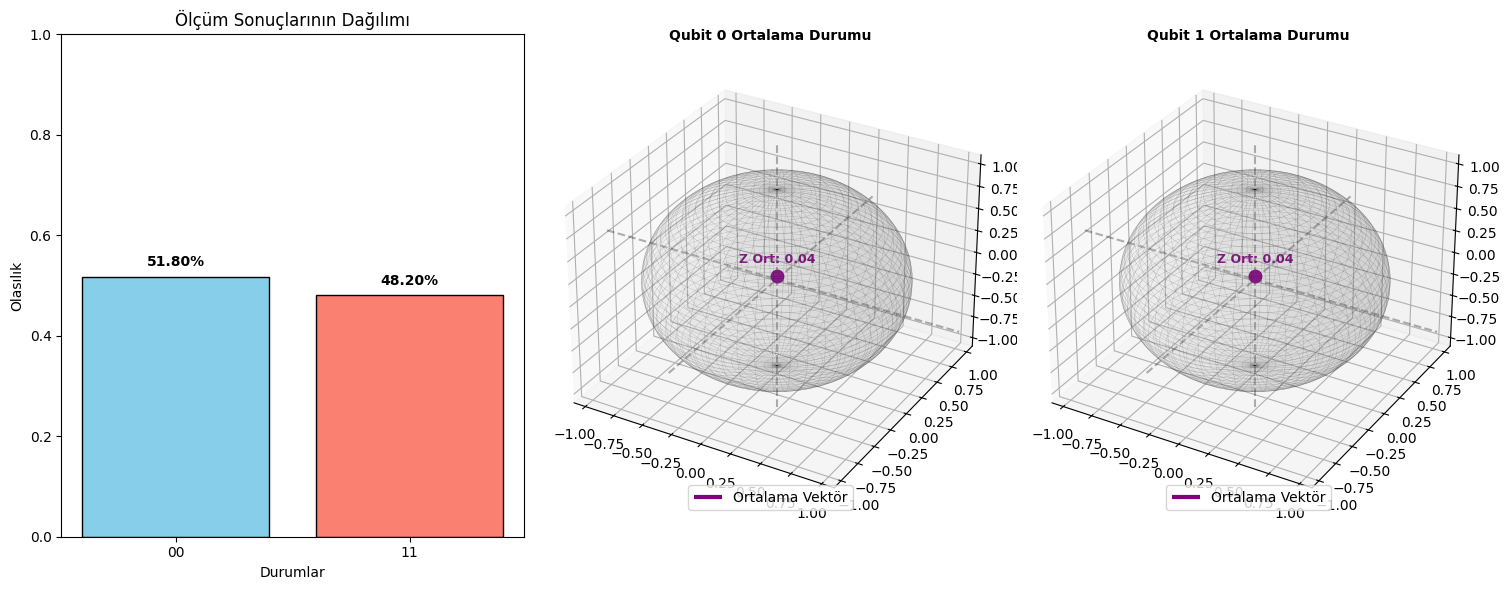

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pennylane as qml

# 500 atışlık çoklu ölçüm cihazı
multi_shot_device = qml.device('default.qubit', wires=2, shots=500)

@qml.qnode(multi_shot_device)
def run_bell_multi_shot():
    qml.Hadamard(wires=0)
    qml.CNOT(wires=[0, 1])
    return qml.counts(wires=[0, 1])

# 500 ölçümün istatistiksel sonuçlarını alalım
counts = run_bell_multi_shot()
print("500 Atış Sonucundaki Dağılım:", counts)

# Olasılıkları hesaplayıp görselleştirelim
states = list(counts.keys())
counts_values = list(counts.values())
total_shots = sum(counts_values)
probabilities = [val / total_shots for val in counts_values]

fig = plt.figure(figsize=(15, 6))

# Sol Panel: Ölçüm Dağılımı Bar Grafiği
ax_bar = fig.add_subplot(131)
ax_bar.bar(states, probabilities, color=['skyblue', 'salmon', 'lightgreen', 'orange'][:len(states)], edgecolor='black')
ax_bar.set_ylabel("Olasılık")
ax_bar.set_xlabel("Durumlar")
ax_bar.set_title("Ölçüm Sonuçlarının Dağılımı")
ax_bar.set_ylim([0, 1.0])
for i, val in enumerate(probabilities):
    ax_bar.text(i, val + 0.02, f"{val:.2%}", ha='center', fontweight='bold')

# Ortalama Bloch vektörlerini hesaplayalım
# Her bir shot için |0> ölçüldüğünde +1, |1> ölçüldüğünde -1 katkısı gelir.
# Bu sayede çoklu atışların ortalamasında Z beklenen değerini elde ederiz.
num_00 = counts.get('00', 0)
num_11 = counts.get('11', 0)
num_01 = counts.get('01', 0)
num_10 = counts.get('10', 0)

# Qubit 0 için 0 olma durumları: 00 ve 01 | 1 olma durumları: 10 ve 11
p_q0_0 = (num_00 + num_01) / total_shots
p_q0_1 = (num_10 + num_11) / total_shots
z_mean_q0 = p_q0_0 * 1.0 + p_q0_1 * (-1.0)

# Qubit 1 için 0 olma durumları: 00 ve 10 | 1 olma durumları: 01 ve 11
p_q1_0 = (num_00 + num_10) / total_shots
p_q1_1 = (num_01 + num_11) / total_shots
z_mean_q1 = p_q1_0 * 1.0 + p_q1_1 * (-1.0)

def draw_average_bloch(ax, z_val, title):
    u = np.linspace(0, 2 * np.pi, 100)
    v = np.linspace(0, np.pi, 100)
    x = np.outer(np.cos(u), np.sin(v))
    y = np.outer(np.sin(u), np.sin(v))
    z = np.outer(np.ones(np.size(u)), np.cos(v))

    ax.plot_surface(x, y, z, color='lightgray', alpha=0.1, edgecolor='k', linewidth=0.3)
    ax.plot([-1.5, 1.5], [0, 0], [0, 0], color='black', linestyle='--', alpha=0.3)
    ax.plot([0, 0], [-1.5, 1.5], [0, 0], color='black', linestyle='--', alpha=0.3)
    ax.plot([0, 0], [0, 0], [-1.5, 1.5], color='black', linestyle='--', alpha=0.3)

    # Ortalama vektörün boyu çoklu atışların simetrisiyle sıfıra yaklaşacaktır
    ax.quiver(0, 0, 0, 0, 0, z_val, color='purple', length=1.0, normalize=False, linewidth=3, arrow_length_ratio=0.2, label='Ortalama Vektör')
    ax.scatter(0, 0, z_val, color='purple', s=80, marker='o')
    ax.text(0, 0, z_val + 0.15, f"Z Ort: {z_val:.2f}", color='purple', fontsize=9, fontweight='bold', ha='center')

    ax.set_xlim([-1.1, 1.1])
    ax.set_ylim([-1.1, 1.1])
    ax.set_zlim([-1.1, 1.1])
    ax.set_title(title, pad=10, fontsize=10, fontweight='bold')
    ax.legend(loc='lower center')

# Sağ Paneller: Qubit 0 ve Qubit 1 Ortalama Bloch Küreleri
ax_q0 = fig.add_subplot(132, projection='3d')
draw_average_bloch(ax_q0, z_mean_q0, "Qubit 0 Ortalama Durumu")

ax_q1 = fig.add_subplot(133, projection='3d')
draw_average_bloch(ax_q1, z_mean_q1, "Qubit 1 Ortalama Durumu")

plt.tight_layout()
plt.show()

# All About Qubits - Pennylane

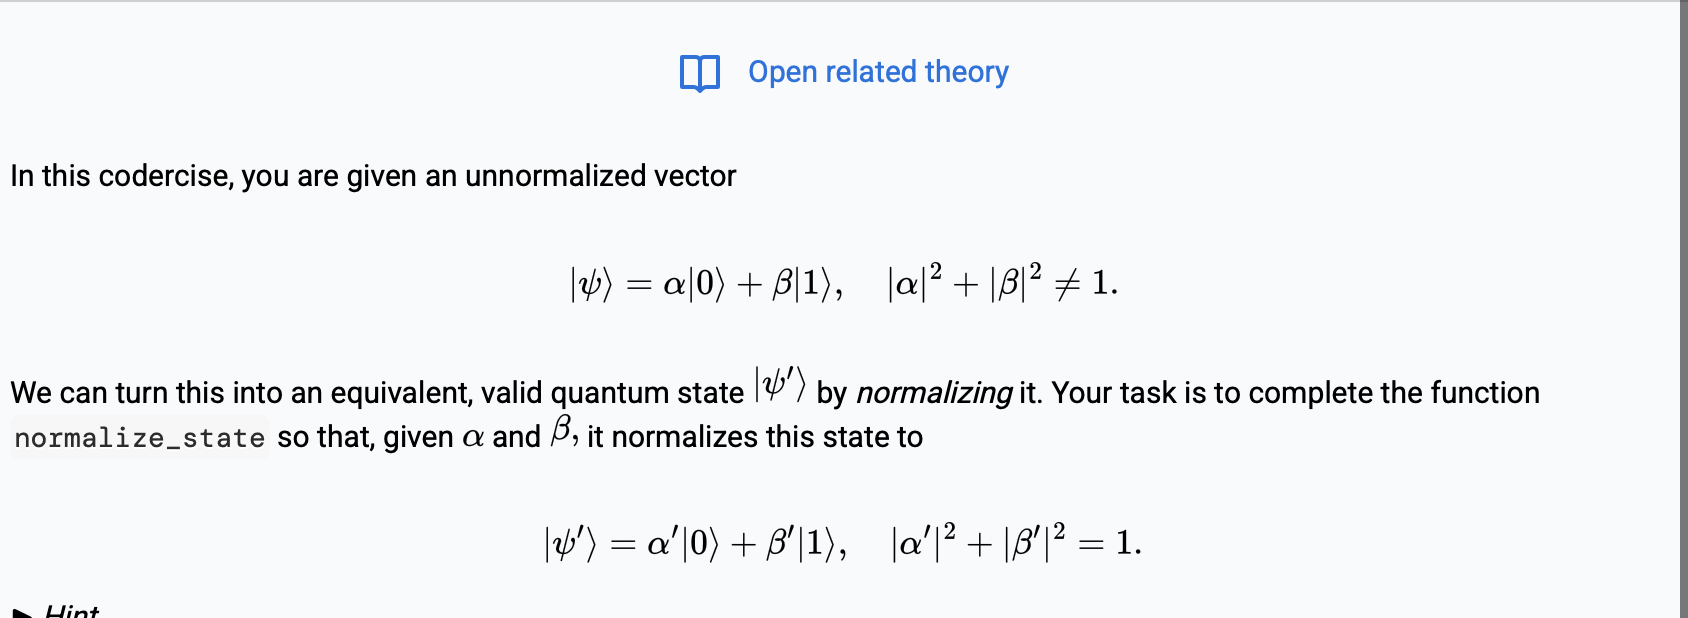

In [29]:
# Here are the vector representations of |0> and |1>, for convenience
ket_0 = np.array([1, 0])
ket_1 = np.array([0, 1])


def normalize_state(alpha, beta):
    """Compute a normalized quantum state given arbitrary amplitudes.

    Args:
        alpha (complex): The amplitude associated with the |0> state.
        beta (complex): The amplitude associated with the |1> state.

    Returns:
        np.array[complex]: A vector (numpy array) with 2 elements that represents
        a normalized quantum state.
    """

    # Norm hesaplama (karekök içinde |alpha|^2 + |beta|^2)
    norm = np.sqrt(np.abs(alpha)**2 + np.abs(beta)**2)

    # Eğer norm sıfırsa sıfıra bölme hatasını önlemek için koruma koyuyoruz
    if norm == 0:
        return np.array([0.0, 0.0], dtype=complex)

    alpha_normalized = alpha / norm
    beta_normalized = beta / norm

    return np.array([alpha_normalized, beta_normalized], dtype=complex)

    normalize


In [43]:
def inner_product(state_1, state_2):
    """Compute the inner product between two states.

    Args:
        state_1 (np.array[complex]): A normalized quantum state vector
        state_2 (np.array[complex]): A second normalized quantum state vector

    Returns:
        complex: The value of the inner product <state_1 | state_2>.
    """

    # İki vektörün kuantum iç çarpımını hesaplamak için np.vdot kullanıyoruz
    # np.vdot, otomatik olarak ilk vektörün (state_1) karmaşık eşleniğini (conjugate) alır
    return np.vdot(state_1, state_2)


# Test your results with this code
ket_0 = np.array([1, 0])
ket_1 = np.array([0, 1])

print(f"<0|0> = {inner_product(ket_0, ket_0)}")
print(f"<0|1> = {inner_product(ket_0, ket_1)}")
print(f"<1|0> = {inner_product(ket_1, ket_0)}")
print(f"<1|1> = {inner_product(ket_1, ket_1)}")


<0|0> = 1
<0|1> = 0
<1|0> = 0
<1|1> = 1


In [47]:
def measure_state(state, num_meas):
    """Simulate a quantum measurement process.

    Args:
        state (np.array[complex]): A normalized qubit state vector.
        num_meas (int): The number of measurements to take

    Returns:
        np.array[int]: A set of num_meas samples, 0 or 1, chosen according to the probability
        distribution defined by the input state.
    """

    # |0> ve |1> durumlarının olasılıklarını hesaplıyoruz (genliklerin mutlak karesi)
    prob_0 = np.abs(state[0])**2
    prob_1 = np.abs(state[1])**2

    # np.random.choice ile olasılıklara göre rastgele seçim yapıyoruz
    return np.random.choice([0, 1], size=num_meas, p=[prob_0, prob_1])


# Test etme amacıyla örnek bir süperpozisyon durumu oluşturup test edelim
psi = np.array([1, 1]) / np.sqrt(2)
samples = measure_state(psi, 20)
print(f"|+> Durumu için 20 Ölçüm Sonucu: {samples}")


|+> Durumu için 20 Ölçüm Sonucu: [1 0 0 0 0 1 0 1 0 0 1 1 0 1 0 0 1 1 1 0]


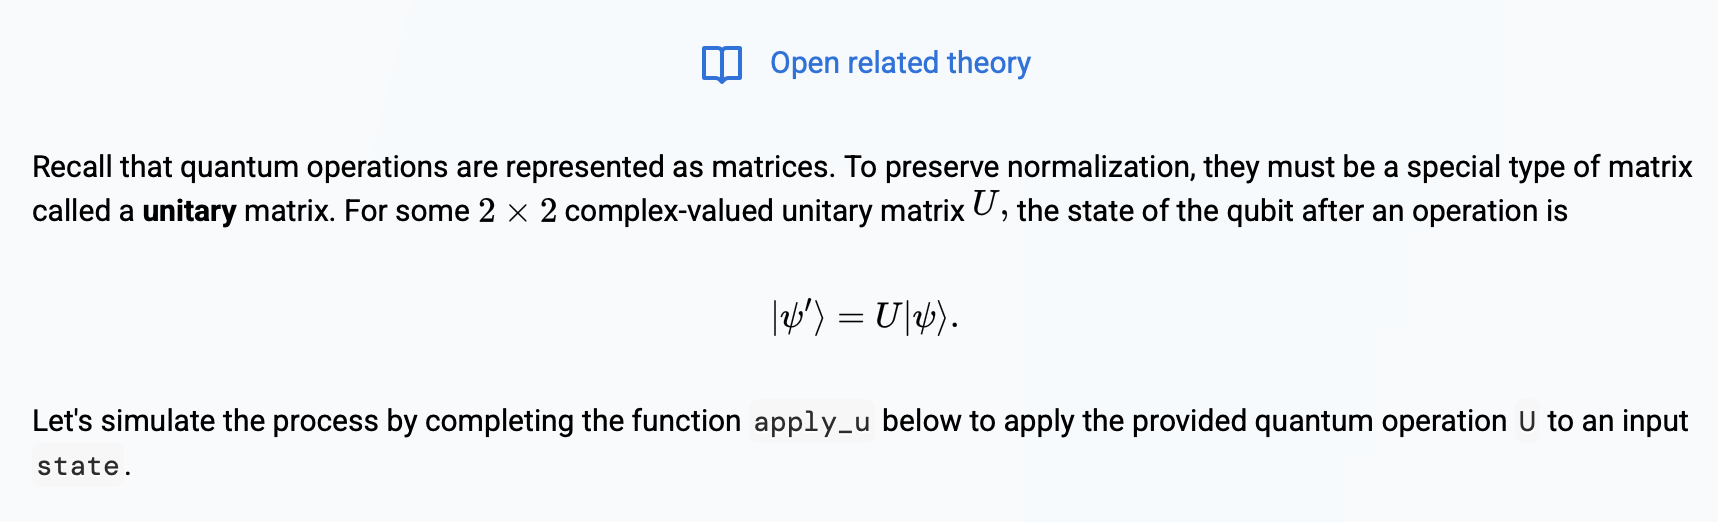

In [32]:
U = np.array([[1, 1], [1, -1]]) / np.sqrt(2)


def apply_u(state):
    """Apply a quantum operation.

    Args:
        state (np.array[complex]): A normalized quantum state vector.

    Returns:
        np.array[complex]: The output state after applying U.
    """

    # U matrisi ile durum vektörünü çarpıyoruz
    return np.dot(U, state)


# Test edelim:
# |0> durumunu tanımlayıp U kapısını uygulayalım
ket_0 = np.array([1, 0], dtype=complex)
resulting_state = apply_u(ket_0)
print(f"U |0> Sonucu: {resulting_state}  (Beklenen: |+> durumu)")


U |0> Sonucu: [0.70710678+0.j 0.70710678+0.j]  (Beklenen: |+> durumu)


In [33]:
U = np.array([[1, 1], [1, -1]]) / np.sqrt(2)


def initialize_state():
    """Prepare a qubit in state |0>.

    Returns:
        np.array[float]: the vector representation of state |0>.
    """

    # |0> durum vektörünü hazırlıyoruz
    return np.array([1.0, 0.0], dtype=complex)


def apply_u(state):
    """Apply a quantum operation."""
    return np.dot(U, state)


def measure_state(state, num_meas):
    """Measure a quantum state num_meas times."""
    p_alpha = np.abs(state[0]) ** 2
    p_beta = np.abs(state[1]) ** 2
    meas_outcome = np.random.choice([0, 1], p=[p_alpha, p_beta], size=num_meas)
    return meas_outcome


def quantum_algorithm():
    """Use the functions above to implement the quantum algorithm described above.

    Try and do so using three lines of code or less!

    Returns:
        np.array[int]: the measurement results after running the algorithm 100 times
    """

    # Durumu ilklendir, U kapısını uygula ve 100 kez ölçüm al
    state = initialize_state()
    transformed_state = apply_u(state)
    return measure_state(transformed_state, 100)


# Algoritmayı test edelim
results = quantum_algorithm()
print(f"Algoritmanın 100 Ölçüm Sonucu:\n{results}")


Algoritmanın 100 Ölçüm Sonucu:
[1 0 1 0 0 1 1 0 1 0 1 0 0 0 1 1 1 0 0 0 1 0 1 0 0 0 0 1 0 0 0 0 1 1 1 0 0
 0 1 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 0 1 0 0 1 1 1 0 0 0 1 1 1 0 1 0
 0 1 0 0 1 1 0 1 1 1 1 1 0 0 1 0 0 0 0 0 1 0 0 0 0 1]


## Quantum Circuits - Pennylane Part2

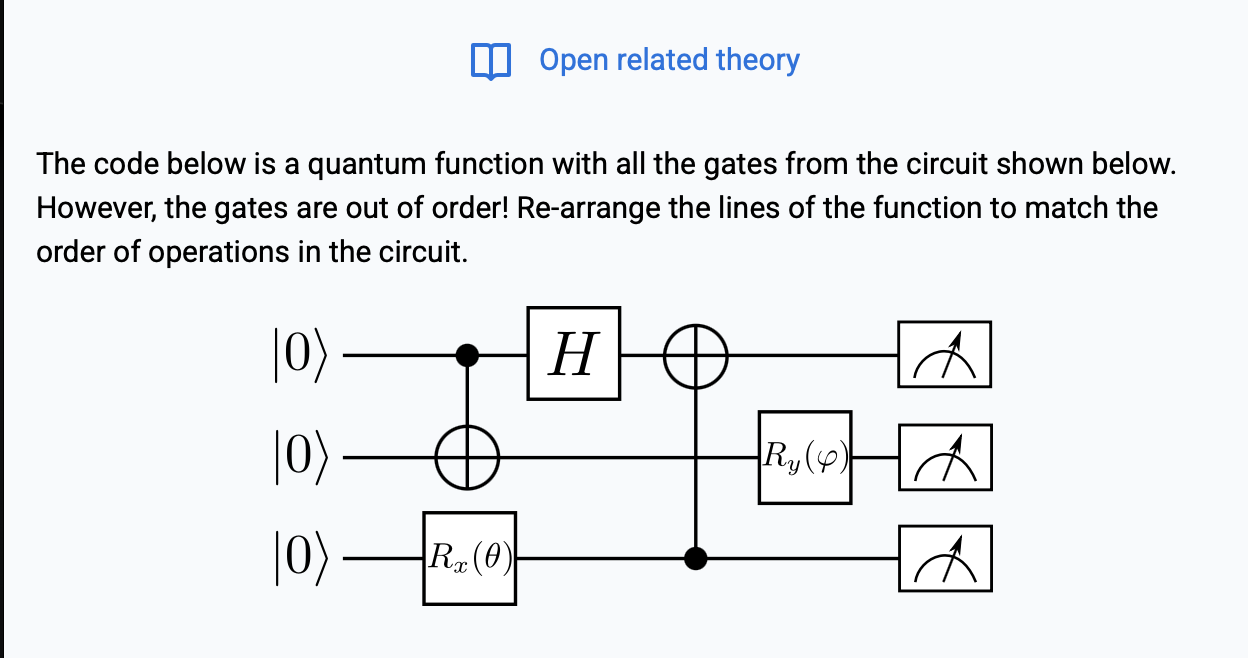

In [38]:
# qp takma adını qml kütüphanesine eşitleyerek şablon kodun sorunsuz çalışmasını sağlıyoruz
qp = qml

# Devre için kullanılacak cihazı oluşturuyoruz (3 qubit)
dev = qml.device("default.qubit", wires=3)

@qml.qnode(dev)
def my_circuit(theta, phi):

# Reorder the Gates within the pennylane for grader
    qp.RX(theta, wires=2)
    qp.CNOT(wires=[0, 1])
    qp.Hadamard(wires=0)
    qp.CNOT(wires=[2, 0])
    qp.RY(phi, wires=1)

    # Olasılık ölçümü
    return qp.probs(wires=[0, 1, 2])

# Örnek parametrelerle devreyi test edelim
theta_val = 0.5
phi_val = 1.2
probabilities = my_circuit(theta_val, phi_val)
print("Çıkış Durumlarının Olasılıkları:", probabilities)


Çıkış Durumlarının Olasılıkları: [0.3197424  0.02084704 0.14965325 0.00975732 0.3197424  0.02084704
 0.14965325 0.00975732]
